# Stochastic calculus in SigAlg: the Itô lemma

## Classical calculus

Let $f(x)$ be a real-valued function of a real variable $x$. As we learned in our first course in calculus, given two numbers $x$ and $\Delta x$, the increment in the function may be approximated using the derivative of $f$, provided that it exists:
$$
f(x+\Delta x) - f(x) \approx f'(x)\, \Delta x. \tag{1}
$$
Generally, the smaller (in magnitude) $\Delta x$, the better the approximation, and in the limit as $\Delta x \to 0$ we obtain an equality
$$
df(x) = f'(x) \, dx. \tag{2}
$$
Intuitively, we think of the *differentials* $df(x)$ and $dx$ as "infinitesimals": They are vanishingly small numbers that $f(x+\Delta x) - f(x)$ and $\Delta x$ "pass through" before they reach $0$ as $\Delta x \to 0$. The existence and rigorous construction of such infinitesimal numbers *is* actually possible; for example, differentials are constructed in the theory of *differential forms* using nothing more than basic linear algebra, while general infinitesimals are constructed in a branch of mathematics called *nonstandard analysis*.

An application of the Fundamental Theorem of Calculus over an interval $[x_1,x_2]$ gives
$$
f(x_2) - f(x_1) = \int_{x_1}^{x_2} f'(x) \, dx. \tag{3}
$$
Or, alternatively, one may obtain this equality by "formally integrating" both sides of (2) to get
$$
\int_{x_1}^{x_2} df(x) = \int_{x_1}^{x_2} f'(x) \, dx, \tag{4}
$$
where the integral on the left is a Riemann-Stieltjes integral with $\int_{x_1}^{x_2} df(x) = f(x_2)-f(x_1)$ trivially. This alternate method does not give us (3) for free, however, since (4) is actually a non-trivial result in the theory of Riemann-Stieltjes integrals. (For more on this theory, see Apostol's book *Mathematical Analysis*.)

Another method for increasing the accuracy of the approximation (1) is to bring in the second-order term from the Taylor expansion of $f$, provided that $f$ is twice-differentiable:
$$
f(x+\Delta x) - f(x) \approx f'(x)\, \Delta x + \frac{1}{2}f''(x) \, \Delta x^2.
$$
As with the first-order approximation (1), this one also improves as $\Delta x \to 0$. However, for twice-differentiable functions like $f$, the second-order term is superfluous if what we are after is the differential $df(x)$, since (2) shows that it may be obtained from the first order piece $f'(x) \, dx$ alone.

Remember that last sentence, for it marks the departure from classical to stochastic calculus, to which we now turn.

## Stochastic calculus

If *stochastic* is a synonym for *random*, then the first thing you should know about stochastic calculus is that it is more than just "random calculus". Indeed, the Lebesgue theory already extends classical integral calculus from determinstic variables to random ones. Rather, the distinctive way in which stochastic calculus extends the classical theory lies not so much in randomness, but in the extreme non-differentiability of the types of objects that it deals with.

To illustrate this point, let's take a look at a simple example in which classical methods still work. Suppose that I give you a random cubic polynomial. By this, I don't mean that I somehow randomly select a *single* cubic polynomial and hand it to you, but rather I give you a *probability distribution* over a collection of cubic polynomials. Formally, we suppose that we have a stochastic process $X_t$, indexed by $t\in [0,\infty)$, with the property that the trajectory $t\mapsto X_t(\omega)$ is a cubic polynomial for each sample point $\omega$.

An example in SigAlg is given in the next code block. It consists of five distinct cubic polynomials, each with equal probability of being realized.

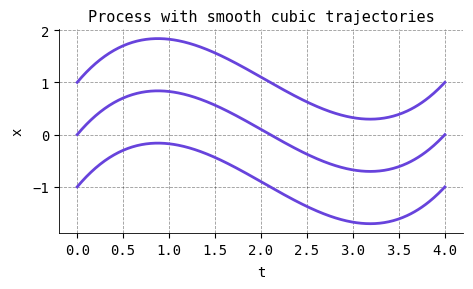

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import sigalg as sa

sa.style.set_style()

n_trajectories = 3
Delta_t = 0.01


def cubics(t: np.ndarray) -> np.ndarray:  # noqa: D103
    polys = [
        lambda t_i, a=a: 0.25 * t_i * (t_i - 2.1) * (t_i - 4) + a
        for a in np.linspace(-1, 1, n_trajectories)
    ]
    return np.array([p(t_i) for p, t_i in zip(polys, t)])


T = sa.Time.continuous(start=0, stop=4, dt=Delta_t)

X = sa.StochasticProcess.from_time(
    T, n_trajectories=n_trajectories
).apply_to_components(cubics, name="X")

_, ax = plt.subplots(figsize=(5, 3))
X.plot_trajectories(ax, y_label="x", x_label="t", colors=[sa.style.purple])
ax.set_title("Process with smooth cubic trajectories")
plt.tight_layout()
plt.show()

Our goal is to construct an integral for the stochastic process $X_t$ and to demonstrate that a form of the classical Fundamental Theorem of Calculus holds. You will see that essentially no new ideas are needed.

We return to the first-order approximation in the previous section that started it all:
$$
f(x_2) - f(x_1) \approx f'(x_1)(x_2-x_1),
$$
where $f(x)$ is a differentiable function of the real variable $x$. Of course, there is nothing to prevent us from replacing the determinsic variables $x_1$ and $x_2$ with random ones. Let's choose two random variables from our cubic stochastic process:
$$
f(X_{t_2}) - f(X_{t_1}) \approx f'(X_{t_1})(X_{t_2} - X_{t_1}).
$$
The left- and right-hand sides of this approximation are random variables, and intuition suggests that the approximation should be good (in some sense) as long as $t_1$ and $t_2$ are near each other since the trajectories of $X_t$ are smooth.

Suppose that we fix an interval $[a,b]$ and a partition
$$
a = t_0 < t_1 < \cdots< t_n = b.
$$
Over each subinterval $[t_k, t_{k+1}]$, we have an approximation of the above form:
$$
f(X_{t_{k+1}}) - f(X_{t_k}) \approx f'(X_{t_k})(X_{t_{k+1}} - X_{t_k}).
$$
If we sum both sides, the left-hand side telescopes and we get
$$
f(X_b) - f(X_a) \approx \sum_{k=0}^{n-1} f'(X_{t_k})(X_{t_{k+1}} - X_{t_k}). \tag{5}
$$
Now, the right-hand side looks a lot like a finite approximation to a Riemann-Stieltjes integral, but again you must be careful to remember that it is actually a sum of random variables, not real numbers. Nevertheless, we are tempted to refine the partition of $[a,b]$, letting the number of subintervals go to $\infty$. Provided that the right-hand side converges (in some mode) to a random variable, it is tempting to call that random variable an *integral*. If it exists and is unique, we shall write it as
$$
\int_a^b f'(X_t) \, dX_t.
$$
Actually, we may as well let the upper limit $b$ vary, replacing it with the variable $t$ and choosing another dummy variable for the integration, in which case we get a stochastic process
$$
\int_a^t f'(X_u) \, dX_u
$$
indexed by $t$. If all this works, then we might be tempted to hypothesize a new Fundamental Theorem, that looks a whole lot like the classical one:
$$
f(X_t) - f(X_a) = \int_a^t f'(X_u) \, dX_u. \tag{6}
$$

The next code block investigates this hypothesized Fundamental Theorem, using our smooth cubic process from above and the function $f(x) = e^x$.

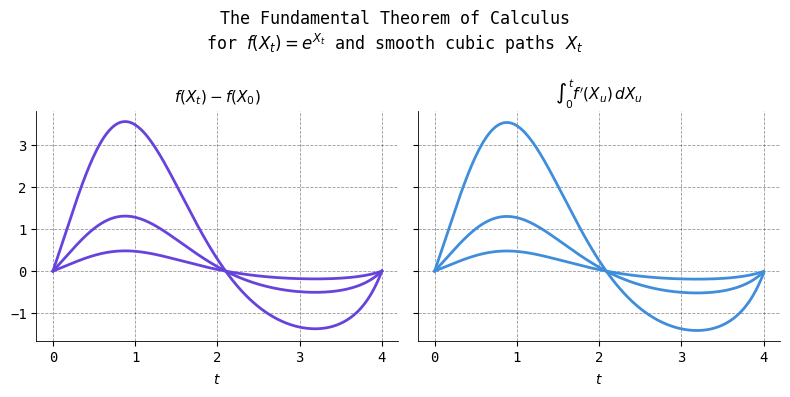

In [18]:
fig, axes = plt.subplots(ncols=2, sharex=True, sharey=True, figsize=(8, 4))

ito_integral = sa.ProcessTransforms.ito_integral  # this will be explained below

increment = ito_integral(integrator=np.exp(X))
FTC = ito_integral(np.exp(X), X)

increment.plot_trajectories(axes[0], colors=[sa.style.purple])
FTC.plot_trajectories(axes[1], colors=[sa.style.blue])

axes[0].set_title(r"$f(X_t) - f(X_0)$")
axes[1].set_title(r"$\int_0^t f'(X_u) \, dX_u$")
axes[0].set_xlabel("$t$")
axes[1].set_xlabel("$t$")

fig.suptitle(
    "The Fundamental Theorem of Calculus\nfor $f(X_t) = e^{X_t}$ and smooth cubic paths $X_t$"
)
plt.tight_layout()
plt.show()

By visual inspection, it appears that our Fundamental Theorem (6) holds, and indeed it *can* be proven rigorously. One just needs to take care to construct the integral precisely, including a description of exactly what *convergence* means. (Roughly, one builds approximations to the integral using so-called *simple processes*, and then takes an appropriate $L^2$-limit.) Setting aside the mathematical subtleties of convergence and existence of this new integral — called an *Itô integral* — at least the reader can see that nothing here involves any new ideas beyond classical ones. 

The reader notices the `ito_integral` method in the code block. In SigAlg, all instances of `StochasticProcess` are discrete-time, constructed from instances of `Time` that specify a partition
$$
a = t_0 < t_1 < \cdots < t_n = b
$$
of an interval $[a,b]$. If $X_t$ and $Z_t$ are two instances of `StochasticProcess` constructed from the same `Time` instance, then we *define* the Itô integral as
$$
\int_a^{t_k} X_u \, dZ_u = \sum_{j=1}^{k} X_{t_{j-1}} (Z_{t_{k}} - Z_{t_{k-1}})
$$
for each $k=1, 2, \ldots, n$, and set $\int_a^a X_u \, dZ_u=0$ when $k=0$. The process $X_t$ is called the *integrand*, while $Z_t$ is called the *integrator*. So, in the code block where we used `ito_integral` to construct an increment in the process, we were leveraging the equality
$$
X_b - X_a = \int_a^b dX_u,
$$
which holds for all processes $X_t$.

The adequacy of the classical theory is due to the smoothness of our cubic process. But the true power of stochastic calculus comes when this nice process is replaced with Brownian motions and other diffusion processes. The reader may recall from a previous SigAlg tutorial that Brownian paths are highly irregular, being non-differentiable everywhere (almost surely). In the next code cell, we plot some simulations drawn from a standard Brownian motion $W_t$ as a reminder.

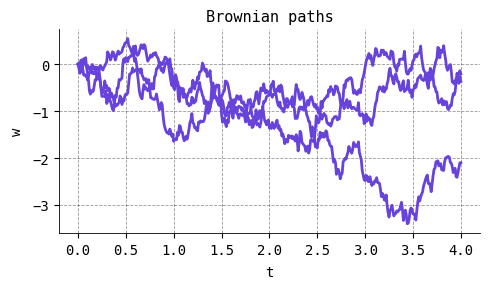

In [19]:
W = sa.BrownianMotion.generate(
    n_trajectories=n_trajectories, index=T, name="W", random_state=42
)

_, ax = plt.subplots(figsize=(5, 3))
W.plot_trajectories(ax, y_label="w", x_label="t", colors=[sa.style.purple])
ax.set_title("Brownian paths")
plt.tight_layout()
plt.show()

Now, let's inspect the classical Fundamental Theorem of Calculus when the smooth cubic trajectories above are replaced with Brownian ones.

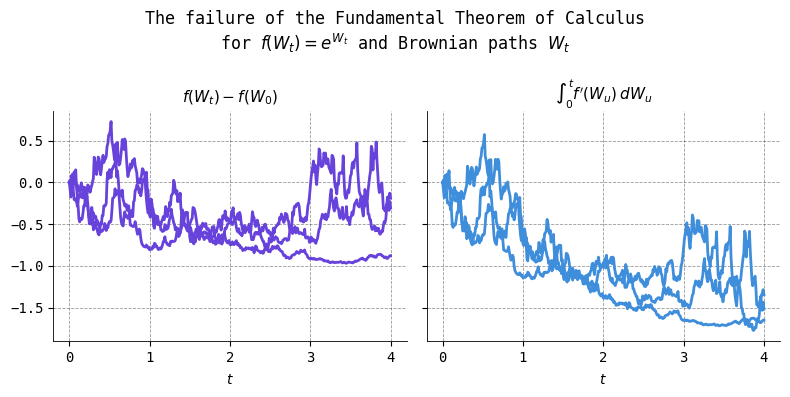

In [20]:
fig, axes = plt.subplots(ncols=2, sharex=True, sharey=True, figsize=(8, 4))

increment = ito_integral(integrator=np.exp(W))
FTC = ito_integral(np.exp(W), W)

increment.plot_trajectories(axes[0], colors=[sa.style.purple])
FTC.plot_trajectories(axes[1], colors=[sa.style.blue])

axes[0].set_title(r"$f(W_t) - f(W_0)$")
axes[1].set_title(r"$\int_0^t f'(W_u) \, dW_u$")
axes[0].set_xlabel("$t$")
axes[1].set_xlabel("$t$")

fig.suptitle(
    "The failure of the Fundamental Theorem of Calculus\nfor $f(W_t) = e^{W_t}$ and Brownian paths $W_t$"
)
plt.tight_layout()
plt.show()

The theorem evidently fails; it appears that
$$
f(W_t) - f(W_0) \neq \int_0^t f'(W_u) \, dW_u
$$
when $W_t$ is a Brownian motion.

We then wonder: Is there a "correction term" that we may add to the right-hand side of the Fundamental Theorem, to recover an equality? The answer is *Yes*. It's called the *Itô correction*. Its definition depends on the so-called *quadratic variation* of a process, to which we now turn.

## Quadratic variation and the Itô correction

Given our discussion so far, the origin of the Itô correction is no mystery.

In [21]:
# import matplotlib.pyplot as plt

# sa.style.set_style()

# ito_integral = sa.ProcessTransforms.ito_integral
# quad_var = sa.ProcessTransforms.quad_var

# fig, axes = plt.subplots(ncols=4, nrows=2, figsize=(12, 6), sharey="row", sharex=True)

# col_titles = [
#     r"$f(X_t)-f(X_0)$",
#     r"$\int_0^t f'(X_u) \, dX_u+\frac{1}{2} \int_0^t f''(X_u) \, d[X]_u$",
#     r"$\int_0^t f'(X_u) \, dX_u$",
#     r"$\frac{1}{2} \int_0^t f''(X_u) \, d[X]_u$",
# ]
# row_labels = ["Smooth paths", "Brownian paths"]

# for i, (process, color) in enumerate(zip([X, W], [sa.style.purple, sa.style.blue])):
#     row_ax = axes[i]

#     if i == 0:
#         for ax, title in zip(row_ax, col_titles):
#             ax.set_title(title)

#     if i == 1:
#         for ax in row_ax:
#             ax.set_xlabel("$t$")

#     row_ax[0].set_ylabel(row_labels[i])

#     finite_difference = ito_integral(integrator=f(process))
#     classical_term = ito_integral(f(process), process)
#     ito_correction = (1 / 2) * ito_integral(f(process), quad_var(process))

#     finite_difference.plot_trajectories(row_ax[0], colors=[color])
#     (classical_term + ito_correction).plot_trajectories(row_ax[1], colors=[color])
#     classical_term.plot_trajectories(row_ax[2], colors=[color])
#     ito_correction.plot_trajectories(row_ax[3], colors=[color])

# fig.suptitle("The Itô correction: smooth paths vs. Brownian paths")
# plt.tight_layout()
# plt.show()